# Scenarios
Simulacion de la poblacion del mosquito (huevos, larvas, pupas y hembras adultas) para distintos escenarios de lluvia y temperatura.

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import CubicSpline

# Funciones para parametros entomologicos

In [18]:
# Modelo de tasas de desarrollo
def develop_rates(x, sigma, a, b, temp_1_2):
  return sigma * ( ( x / 298 ) * np.exp( ( a / R ) * ( 1 / 298 - 1 / x) ) ) / ( 1 + np.exp ( ( b / R ) * ( 1 / temp_1_2 - 1 / x) ) )

# Modelo de perdida de viabilidad
def vial(x, b):
    return np.exp(-b * x)

# Funciones para la lluvia

In [19]:
# Suma acumulada de los ultimos window_size dias
def rolling_sum(data, window_size):
    if window_size > len(data):
        raise ValueError("Window size cannot be larger than data length")

    rolling_sums = np.zeros_like(data)

    for i in range(len(data)):
        start_index = max(0, i - window_size + 1)
        end_index = i + 1
        rolling_sums[i] = np.sum(data[start_index:end_index])

    return rolling_sums

# Normaliza la lluvia acumulada: 0 si supera cmax (percentil 97.5) o es negativa
def calculate_pn(cn_data):
  cmax = np.percentile(cn_data, 97.5)
  pn_array = np.zeros_like(cn_data)
  for i in range(len(cn_data)):
      cn_value = cn_data[i]
      if cn_value > cmax or cn_value < 0:
          pn_array[i] = 0
      else:
          pn_array[i] = cn_value / cmax
  return pn_array

# Perdida de viabilidad de los huevos segun los dias sin lluvia
def calculate_epsilon(Pi, thresh):
  epsilon = []
  count = 0
  for i in range(len(Pi)):
    epsilon.append(vial(count,*params_vial))
    if Pi[i] > thresh:
      count = 0
    else:
      count += 1
  return np.array(epsilon)

# Parametros para el modelo

In [20]:
# Numero de Boltzmann
R = 8.31446261815324

# Eclosión
sigma_1 = 0.01066*24
a_1 = 10798.18
b_1 = 100000
temp_1_2_1 = 14184.50
params_e = [sigma_1, a_1, b_1, temp_1_2_1]

# Viabilidad
params_vial = [0.0737]

# Pupacion
sigma_2 = 0.00873*24
a_2 = 26018.51
b_2 = 55990.75
temp_1_2_2 = 304.58
params_l = [sigma_2, a_2, b_2, temp_1_2_2]

# Desarrollo de la pupa
sigma_3 = 0.01610*24
a_3 = 14931.94
b_3 = -472379.00
temp_1_2_3 = 148.45
params_p = [sigma_3, a_3, b_3, temp_1_2_3]

# Tasa de oviposicion
phi_coefficients = [-1.515e-4, 1.015e-2, -2.124e-1, 1.8, -5.4]
p_fi = np.poly1d(phi_coefficients)

# Mortalidad de la hembra
mu_m_coefficients = [3.809e-6, -3.408e-4, 1.116e-2, -1.590e-1, 8.692e-1]
p_u_m = np.poly1d(mu_m_coefficients)

# Mortalidad de la larva
mu_l_coefficients = [7.503e-6, -7.538e-4,2.735e-2, -4.191e-1, 2.315]
p_u_l = np.poly1d(mu_l_coefficients)

# Mortalidad de la pupa
mu_p_coefficients = [4.395e-7,7.060e-4, -3.248e-2,4.256e-1]
p_u_p = np.poly1d(mu_p_coefficients)

# Mortalidad de huevos
u_e = 0.01

# Parametros de la simulacion

In [21]:
# Tiempo [dias]
ti = np.arange(0, 1000)

# Condiciones iniciales [huevos, larvas, pupas, hembras adultas]
valores_iniciales = [1000, 500, 300, 150]

# Capacidad de carga y efecto de la lluvia acumulada
K = 1000
alpha = 1

# Umbral de lluvia para reiniciar el conteo de dias secos
threshes = [1e-3]

# Ventana de lluvia acumulada [dias]
n_rain = 19

# Escenarios

In [22]:
# Lluvia ligera (poco frecuente) y lluvia fuerte (muy frecuente)
rng = np.random.default_rng(4221)
rain_hour_low = 0.2
rain_hour_high = 2
Pi_low = rng.poisson(lam=rain_hour_low, size=len(ti))/1000
Pi_high = rng.poisson(lam=rain_hour_high, size=len(ti))/1000

# Lluvia acumulada normalizada
P_low = calculate_pn(rolling_sum(Pi_low, n_rain))
P_high = calculate_pn(rolling_sum(Pi_high, n_rain))

# Temperaturas altas y bajas
temp_amp = 2.5
tempi_high = 30 + temp_amp*np.cos(2*np.pi*(1/365)*ti)
tempi_low = 15 + temp_amp*np.cos(2*np.pi*(1/365)*ti)

# Escenarios: nombre -> (lluvia, lluvia acumulada, temperatura)
escenarios = {
    'low_rain_low_temp': (Pi_low, P_low, tempi_low),
    'low_rain_high_temp': (Pi_low, P_low, tempi_high),
    'high_rain_low_temp': (Pi_high, P_high, tempi_low),
    'high_rain_high_temp': (Pi_high, P_high, tempi_high),
}

# Simulacion del modelo

In [23]:
# Calcula epsilon, Q_0 y la dinamica de la poblacion para un escenario
def simulate(Pi, P, tempi, thresh):
  tempi_k = tempi + 273.15
  P_t = CubicSpline(ti, P)

  # Parametros
  epsilon = calculate_epsilon(Pi, thresh)
  sigma_e_efect = develop_rates(tempi_k,*params_e)*epsilon
  sigma_l = develop_rates(tempi_k,*params_l)
  sigma_p = develop_rates(tempi_k,*params_p)
  fi = np.maximum(p_fi(tempi), 0)
  u_l = np.maximum(p_u_l(tempi), 0)
  u_p = np.maximum(p_u_p(tempi), 0)
  u_m = np.maximum(p_u_m(tempi), 0)

  # Calculo de Q_0
  Q_0 = (fi*sigma_p*sigma_l*sigma_e_efect)/(2*u_m*(sigma_p+u_p)*(sigma_l+u_l)*(sigma_e_efect+u_e))

  # Parametros en funcion del tiempo
  sigma_e_t = CubicSpline(ti, sigma_e_efect)
  sigma_l_t = CubicSpline(ti, sigma_l)
  sigma_p_t = CubicSpline(ti, sigma_p)
  phi_t = CubicSpline(ti, fi)
  mu_l_t = CubicSpline(ti, u_l)
  mu_p_t = CubicSpline(ti, u_p)
  mu_m_t = CubicSpline(ti, u_m)

  # Sistema de ecuaciones
  def deriv(t, y):
    E, L, P_, M = y
    C = K*(1 + alpha*np.absolute(P_t(t)))
    dEdt = 0.5*phi_t(t) * ( 1 - E / C ) * M - ( sigma_e_t(t) + u_e) * E  # Eggs
    dLdt = sigma_e_t(t) * E - ( sigma_l_t(t) + mu_l_t(t)) * L            # Larvae
    dPdt = sigma_l_t(t) * L - ( sigma_p_t(t) + mu_p_t(t)) * P_           # Pupae
    dMdt = sigma_p_t(t) * P_ - ( mu_m_t(t)) * M                          # Female adult
    return [dEdt, dLdt, dPdt, dMdt]

  ret = solve_ivp(deriv, [np.min(ti), np.max(ti)], valores_iniciales, t_eval=ti, method='LSODA')

  return {'epsilon': epsilon, 'Q_0': Q_0,
          'E': ret.y[0], 'L': ret.y[1], 'P': ret.y[2], 'A': ret.y[3]}

In [24]:
# Resultados de todos los escenarios para cada umbral
results = {}
for thresh in threshes:
  results[thresh] = {}
  for name, (Pi, P, tempi) in escenarios.items():
    results[thresh][name] = simulate(Pi, P, tempi, thresh)

# Graficos

In [25]:
plt.rcParams.update({'font.size': 22})

# Grafico de precipitacion y temperatura

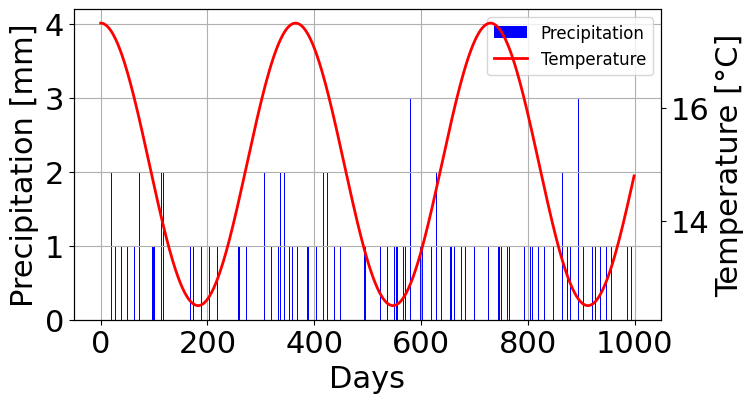

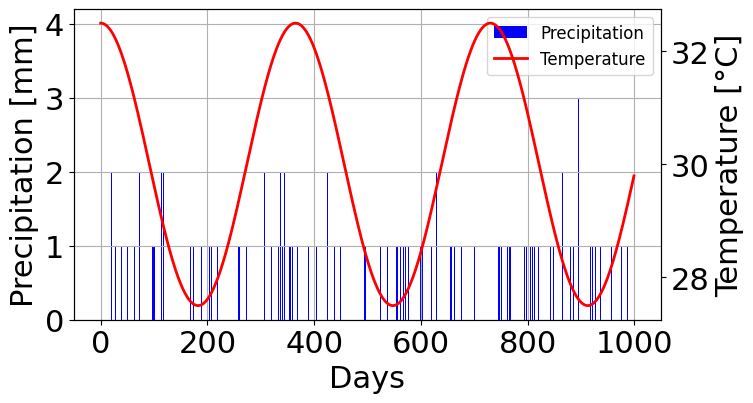

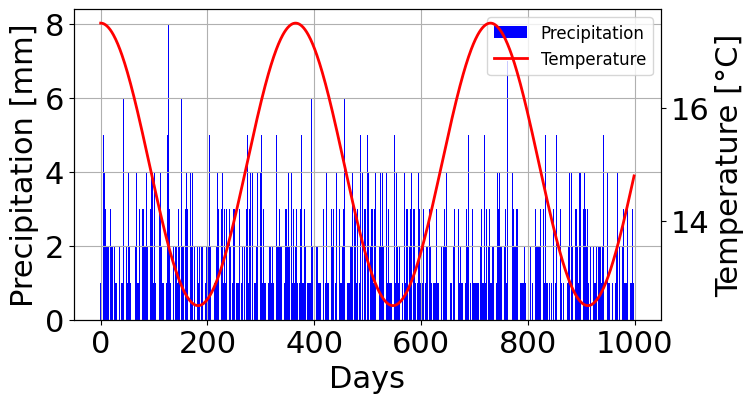

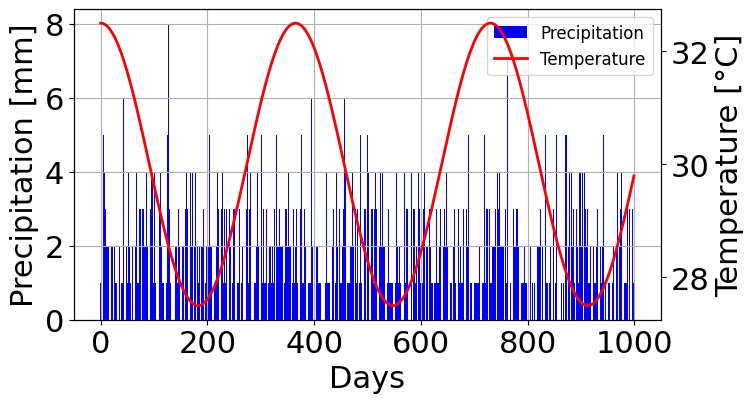

In [26]:
for name, (Pi, P, tempi) in escenarios.items():
  fig = plt.figure(figsize=(8, 4.5))
  ax = fig.add_subplot(111)

  # Precipitacion
  bars = ax.bar(ti, Pi*1000, color='blue', label='Precipitation')
  ax.set_xlabel('Days')
  ax.set_ylabel('Precipitation [mm]')
  ax.grid()

  # Temperatura en el eje secundario
  ax2 = ax.twinx()
  line, = ax2.plot(ti, tempi, color='red', lw=2, label='Temperature')
  ax2.set_ylabel('Temperature [°C]')

  ax.legend([bars, line], ['Precipitation', 'Temperature'], loc='upper right', fontsize="12")
  plt.tight_layout()
  plt.show()

# Grafico de lluvia acumulada

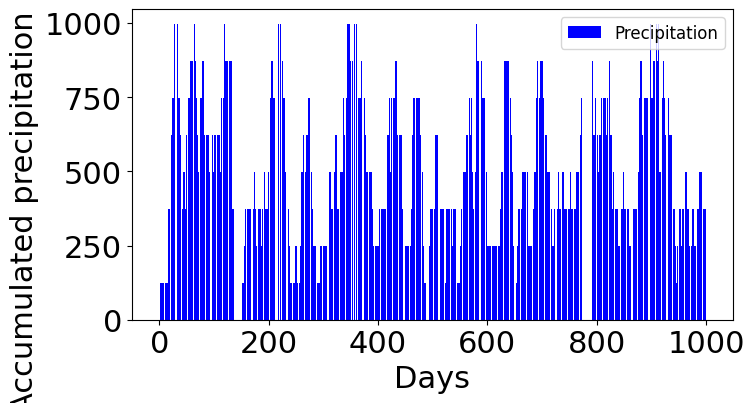

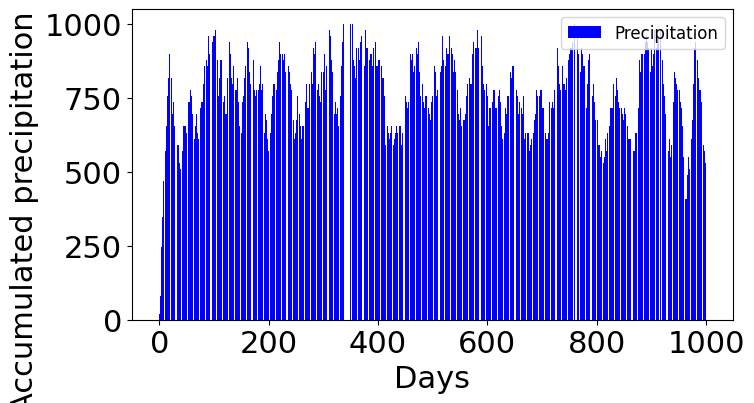

In [27]:
for P in [P_low, P_high]:
  fig = plt.figure(figsize=(8, 4.5))
  ax = fig.add_subplot(111)

  ax.bar(ti, P*1000, color='blue', label='Precipitation')
  ax.set_xlabel('Days')
  ax.set_ylabel('Accumulated precipitation [mm]')
  ax.legend(loc='upper right', fontsize="12")

  plt.tight_layout()
  plt.show()

# Grafico de $\epsilon$

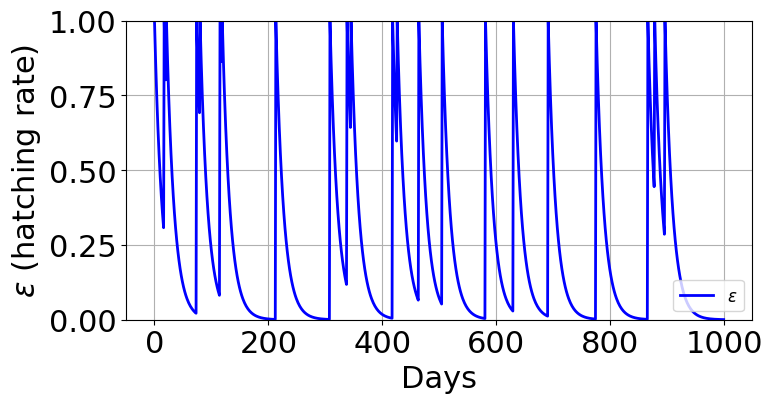

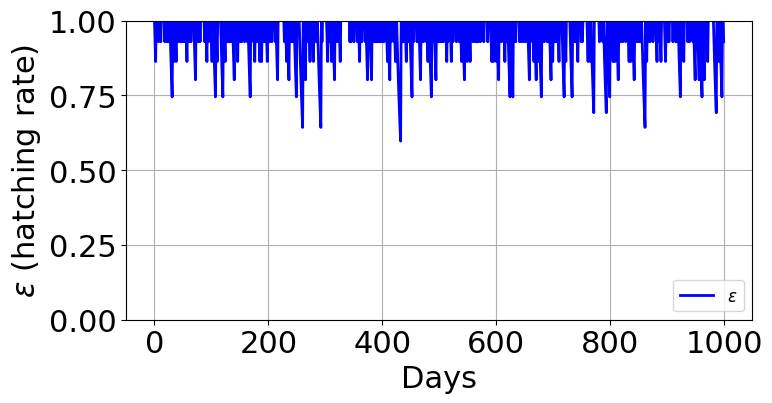

In [28]:
# Epsilon depende solo de la lluvia
for thresh in threshes:
  for name in ['low_rain_low_temp', 'high_rain_low_temp']:
    fig = plt.figure(figsize=(8, 4.5))
    ax = fig.add_subplot(111)

    ax.plot(ti, results[thresh][name]['epsilon'], 'blue', lw=2, label=r'$\epsilon$')
    ax.set_xlabel('Days')
    ax.set_ylabel(r'$\epsilon$ (hatching rate)')
    ax.set_ylim([0, 1])
    ax.legend(loc='lower right', fontsize="12")
    ax.grid(True)

    plt.tight_layout()
    plt.show()

# Grafico de $Q_0$

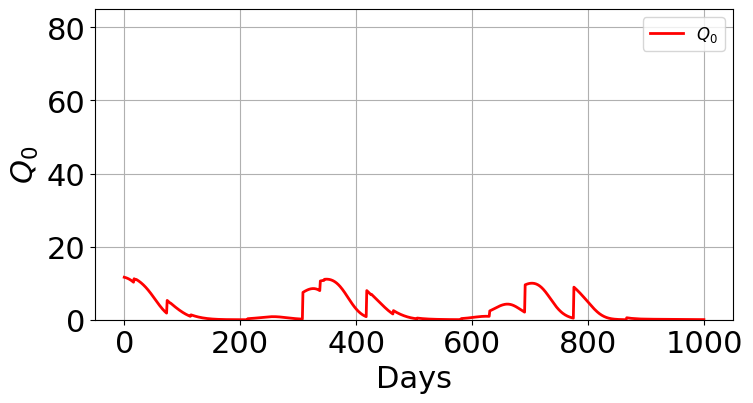

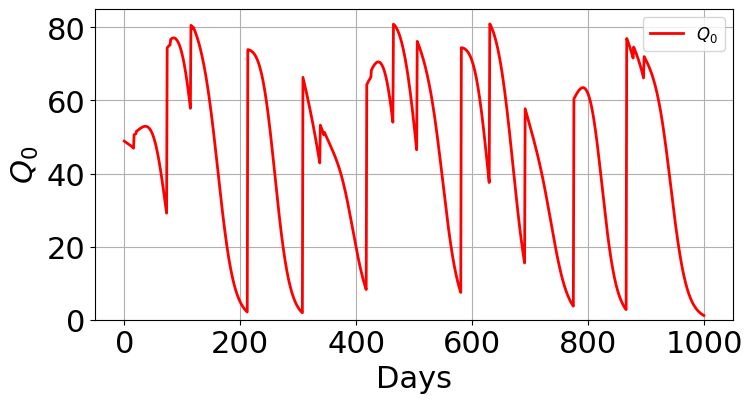

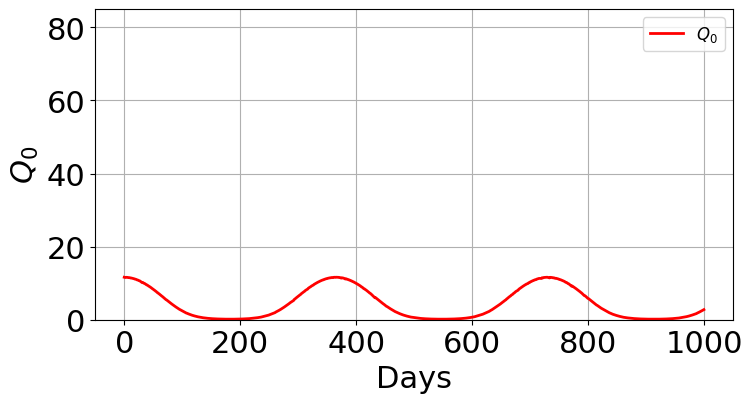

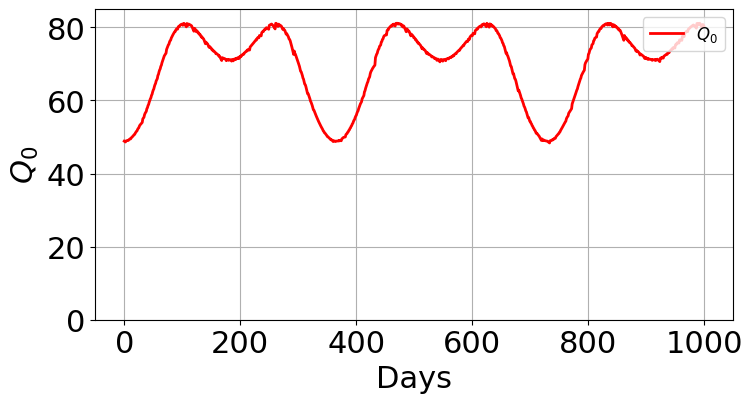

In [29]:
for thresh in threshes:
  for name in escenarios:
    fig = plt.figure(figsize=(8, 4.5))
    ax = fig.add_subplot(111)

    ax.plot(ti, results[thresh][name]['Q_0'], 'red', lw=2, label='$Q_0$')
    ax.set_xlabel('Days')
    ax.set_ylabel('$Q_0$')
    ax.set_ylim([0, 85])
    ax.legend(loc='upper right', fontsize="12")
    ax.grid(True)

    plt.tight_layout()
    plt.show()

# Grafico de la poblacion de mosquitos

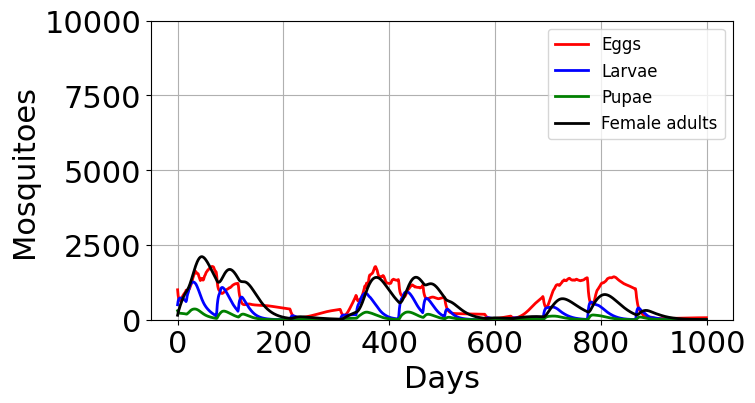

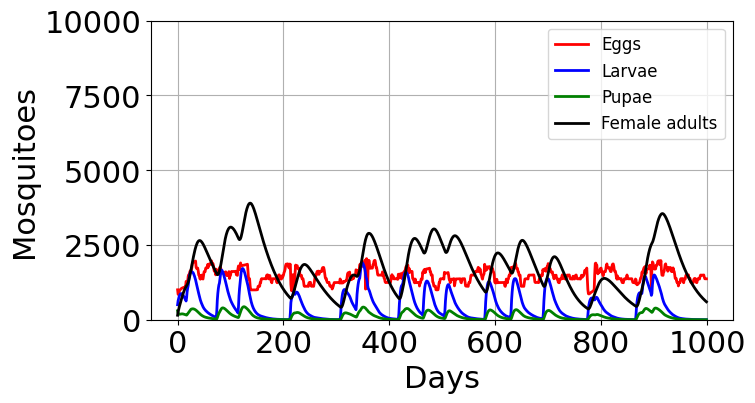

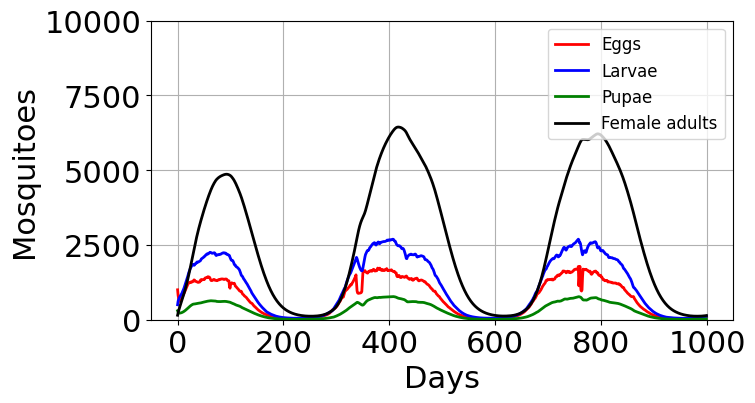

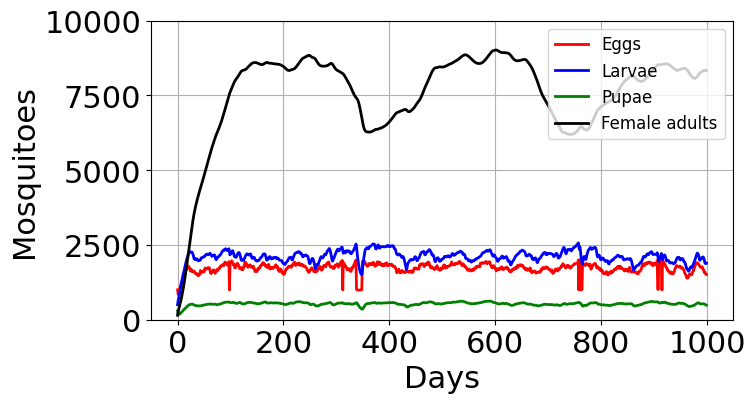

In [30]:
y_lim_max = 10000

for thresh in threshes:
  for name in escenarios:
    res = results[thresh][name]
    fig = plt.figure(figsize=(8, 4.5))
    ax = fig.add_subplot(111)

    ax.plot(ti, res['E'], 'red', lw=2, label='Eggs')
    ax.plot(ti, res['L'], 'blue', lw=2, label='Larvae')
    ax.plot(ti, res['P'], 'green', lw=2, label='Pupae')
    ax.plot(ti, res['A'], 'black', lw=2, label='Female adults')
    ax.set_xlabel('Days')
    ax.set_ylabel('Mosquitoes')
    ax.set_ylim([0, y_lim_max])
    ax.legend(loc='upper right', fontsize="12")
    ax.grid(True)

    plt.tight_layout()
    plt.show()